# Langkah-Langkah Praktikum

## 1. Menyiapkan Dataset Sintetis

In [1]:
import numpy as np
import pandas as pd
rng = np.random.default_rng(42)
n = 500
amount = rng.lognormal(mean=5.0, sigma=1.0, size=n)
hour = rng.integers(0, 24, n)
new_device = rng.binomial(1, 0.25, n)
foreign_ip = rng.binomial(1, 0.12, n)
score = -4.5 + 0.45*(amount > 300) + 1.1*new_device + 1.5*foreign_ip + 0.7*(hour < 5)
prob = 1/(1+np.exp(-score))
isFraud = rng.binomial(1, prob)
df = pd.DataFrame({'amount':amount.round(2), 'hour':hour,
                   'new_device':new_device, 'foreign_ip':foreign_ip,
                   'isFraud':isFraud})
print(df.head())
print('Distribusi kelas:')
print(df['isFraud'].value_counts())

   amount  hour  new_device  foreign_ip  isFraud
0  201.28     9           0           0        0
1   52.46     8           0           0        0
2  314.33    17           1           0        0
3  380.15     3           0           0        0
4   21.09     5           1           0        0
Distribusi kelas:
isFraud
0    484
1     16
Name: count, dtype: int64


Penjelasan: Bagian ini membuat dataset sintetis transaksi sebanyak 500 baris menggunakan generator acak NumPy dengan seed 42 (`default_rng(42)`). Terdapat empat fitur, yaitu `amount` (nominal transaksi, berdistribusi lognormal), `hour` (jam transaksi 0–23), `new_device` (1 jika memakai perangkat baru, peluang 25%), dan `foreign_ip` (1 jika berasal dari IP luar negeri, peluang 12%). Label `isFraud` dihasilkan dari probabilitas logistik: skor dasar bernilai negatif (−4,5) membuat fraud jarang terjadi, lalu dinaikkan oleh pola risiko seperti nominal di atas 300, perangkat baru, IP luar negeri, dan transaksi dini hari (sebelum 05.00), kemudian label ditarik dengan distribusi binomial. Catat proporsi fraud; hasil deterministik selama kode dan versi generator tetap sama. Proporsi fraud perlu dicatat karena menunjukkan tingkat ketidakseimbangan kelas: dari 500 transaksi terdapat 484 normal dan 16 fraud (16/500 = 3,2%), sehingga fraud sangat minoritas dan accuracy saja tidak cukup untuk evaluasi di bagian berikutnya. Hasilnya deterministik karena data dibangkitkan dengan seed tetap (42), sehingga dijalankan berulang kali akan menghasilkan dataset dan angka yang sama; namun jika kode, nilai seed, atau versi generator NumPy berubah, jumlah fraud dan angka-angka lain bisa berbeda.

## 2. Membagi Data dan Melatih Model

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X = df.drop(columns='isFraud')
y = df['isFraud']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)
model = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print('Data uji:', len(y_test))

Data uji: 150


Penjelasan: Bagian ini memisahkan fitur (`X`) dari label (`y` = `isFraud`), lalu membagi data menjadi 70% data latih dan 30% data uji dengan `test_size=0.30` dan `random_state=42` agar pembagiannya dapat direproduksi, sehingga data uji berjumlah 150 transaksi. Stratify menjaga proporsi kelas pada data latih dan uji; artinya perbandingan fraud terhadap normal pada data latih maupun data uji dibuat sama dengan data aslinya (±3,2%). Ini penting karena fraud sangat sedikit (16 dari 500): tanpa stratify, pembagian acak bisa membuat data uji nyaris tidak memuat fraud sehingga evaluasi tidak bermakna, sedangkan dengan stratify data uji memuat 5 fraud dan 145 normal (data latih memuat 11 fraud). Model yang dilatih adalah Decision Tree dengan `max_depth=4` untuk membatasi kedalaman pohon agar tidak overfitting; class_weight balanced memberi bobot lebih besar pada kelas minoritas, yaitu bobot kelas dihitung berbanding terbalik dengan jumlahnya (pada data latih 350 baris, bobot fraud sekitar 15,9 dan bobot normal sekitar 0,52, atau fraud sekitar 31 kali lebih berat). Dengan demikian kesalahan pada fraud lebih diperhitungkan saat pelatihan dan model tidak hanya menebak kelas mayoritas. Setelah `fit`, model memprediksi data uji lewat `predict` dan hasilnya disimpan di `y_pred` untuk dievaluasi.

## 3. Menghitung Confusion Matrix

In [3]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred, labels=[0,1])
tn, fp, fn, tp = cm.ravel()
print('Confusion matrix:\n', cm)
print(f'TP={tp}, TN={tn}, FP={fp}, FN={fn}')

Confusion matrix:
 [[113  32]
 [  3   2]]
TP=2, TN=113, FP=32, FN=3


Penjelasan: Bagian ini menghitung confusion matrix dari label aktual `y_test` dan prediksi `y_pred` dengan `confusion_matrix(..., labels=[0,1])`, sehingga urutan baris dan kolom konsisten (0 = normal, 1 = fraud); baris mewakili kelas aktual dan kolom mewakili kelas prediksi. Matriks 2×2 itu diratakan dengan `ravel()` menjadi empat nilai berurutan, yaitu TN, FP, FN, dan TP. Catat empat nilai yang dihasilkan dari eksekusi: TN = 113 (normal yang benar diprediksi normal), FP = 32 (normal yang salah ditandai fraud), FN = 3 (fraud yang lolos sebagai normal), dan TP = 2 (fraud yang benar terdeteksi). Keempat nilai perlu dicatat karena seluruh metrik evaluasi dihitung dari sana, dan juga bisa dipakai untuk memeriksa kebenaran hasil: TN + FP = 145 sesuai jumlah transaksi normal pada data uji, FN + TP = 5 sesuai jumlah fraud, dan totalnya 150 sesuai ukuran data uji. Terlihat pula bahwa dari 5 fraud model hanya menangkap 2, sementara 32 transaksi normal ikut ditandai sebagai fraud.

## 4. Perhitungan Manual dan Verifikasi

In [4]:
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = 2*precision*recall/(precision+recall) if precision+recall else 0
print(f'Accuracy={accuracy:.3f}; Precision={precision:.3f}; Recall={recall:.3f}; F1={f1:.3f}')
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
print(accuracy_score(y_test,y_pred), precision_score(y_test,y_pred,zero_division=0),
      recall_score(y_test,y_pred,zero_division=0), f1_score(y_test,y_pred,zero_division=0))

Accuracy=0.767; Precision=0.059; Recall=0.400; F1=0.103
0.7666666666666667 0.058823529411764705 0.4 0.10256410256410256


Penjelasan: Bagian ini menghitung empat metrik evaluasi secara manual dari nilai TP, TN, FP, dan FN, yaitu accuracy = (TP+TN)/(TP+TN+FP+FN), precision = TP/(TP+FP), recall = TP/(TP+FN), dan F1 = 2·precision·recall/(precision+recall), dengan pengaman `if ... else 0` agar tidak terjadi pembagian dengan nol. Hasil manualnya adalah accuracy 0,767, precision 0,059, recall 0,400, dan F1 0,103. Kemudian nilai yang sama dihitung ulang memakai fungsi scikit-learn (`accuracy_score`, `precision_score`, `recall_score`, `f1_score`) sebagai verifikasi. Bandingkan kedua hasil: perhitungan manual dan fungsi scikit-learn harus sama, selain pembulatan tampilan. Keduanya harus sama karena memakai rumus yang sama dan masukan yang sama (TP, TN, FP, FN dari prediksi yang sama); satu-satunya perbedaan yang wajar hanya cara menampilkan angka, misalnya precision manual tercetak 0,059 sedangkan scikit-learn menampilkan 0,0588 (nilai aslinya 2/34). Jika hasilnya berbeda jauh, berarti ada kesalahan, misalnya rumus tertukar atau urutan TN/FP/FN/TP keliru. Pada eksekusi ini keduanya sama, sehingga perhitungan manual terverifikasi benar.

## 5. Visualisasi Confusion Matrix

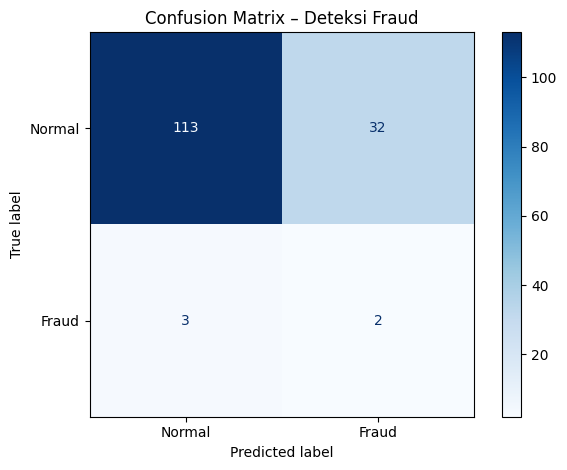

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay(confusion_matrix=cm,
                       display_labels=['Normal','Fraud']).plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix – Deteksi Fraud')
plt.tight_layout()
plt.show()

Penjelasan: Bagian ini memvisualisasikan confusion matrix `cm` menjadi heatmap dengan `ConfusionMatrixDisplay` (label sumbu Normal dan Fraud, warna `Blues`, `values_format='d'` agar angka tampil sebagai bilangan bulat), diberi judul "Confusion Matrix – Deteksi Fraud", lalu ditampilkan dengan `plt.show()`. Baris menunjukkan kelas aktual dan kolom menunjukkan kelas prediksi, sehingga diagonal utama (TN = 113 dan TP = 2) adalah prediksi yang benar, sedangkan sel di luar diagonal (FP = 32 dan FN = 3) adalah kesalahan; semakin gelap warna sel, semakin besar jumlahnya, sehingga sel TN langsung terlihat paling dominan. Jelaskan sel FN dan FP berdasarkan konsekuensi praktisnya. Sel FN (3 transaksi) adalah fraud yang salah dianggap normal, sehingga transaksi berbahaya lolos tanpa tindakan dan dapat menimbulkan kerugian finansial langsung bagi pelanggan atau bank serta risiko reputasi; kesalahan ini bersifat diam-diam karena baru diketahui setelah kerugian terjadi. Sel FP (32 transaksi) adalah transaksi normal yang salah ditandai fraud, sehingga pelanggan yang sah mengalami transaksi ditolak atau akun diblokir, tim verifikasi harus memeriksa alarm yang tidak perlu, dan kepercayaan pelanggan bisa menurun. Pada hasil ini FP jauh lebih banyak daripada FN, artinya model cenderung terlalu sering mengeluarkan alarm dan tetap melewatkan 3 dari 5 fraud, sehingga biaya relatif kedua jenis kesalahan perlu dipertimbangkan saat memilih metrik dan threshold.

## 6. Interpretasi dan Studi Kasus
Dalam deteksi fraud, FN berarti transaksi fraud tidak terdeteksi dan berpotensi menimbulkan kerugian; FP
berarti transaksi normal ditandai fraud dan dapat mengganggu pelanggan. Recall tinggi membantu
mengurangi fraud yang lolos, tetapi dapat meningkatkan alarm palsu. Pilihan metrik perlu
mempertimbangkan biaya masing-masing kesalahan.

## 7. Eksperimen: Baseline Semua Normal

In [6]:
baseline = np.zeros(len(y_test), dtype=int)
from sklearn.metrics import classification_report
print('Baseline accuracy:', accuracy_score(y_test, baseline))
print(classification_report(y_test, baseline, labels=[0,1], zero_division=0))
print('Decision Tree:')
print(classification_report(y_test, y_pred, labels=[0,1], zero_division=0))

Baseline accuracy: 0.9666666666666667
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       145
           1       0.00      0.00      0.00         5

    accuracy                           0.97       150
   macro avg       0.48      0.50      0.49       150
weighted avg       0.93      0.97      0.95       150

Decision Tree:
              precision    recall  f1-score   support

           0       0.97      0.78      0.87       145
           1       0.06      0.40      0.10         5

    accuracy                           0.77       150
   macro avg       0.52      0.59      0.48       150
weighted avg       0.94      0.77      0.84       150



Penjelasan: Bagian ini membuat baseline sederhana, yaitu model yang selalu memprediksi "normal" untuk semua data uji (`np.zeros(len(y_test))`), lalu membandingkannya dengan Decision Tree memakai `accuracy_score` dan `classification_report` yang menampilkan precision, recall, dan F1 untuk tiap kelas. Bandingkan akurasi baseline dengan recall kelas fraud. Model yang selalu memprediksi normal bisa memperoleh akurasi tinggi ketika fraud jarang, tetapi recall fraud = 0. Pada data uji ini terdapat 145 normal dan 5 fraud, sehingga baseline benar pada seluruh 145 transaksi normal dan memperoleh akurasi 145/150 = 0,967, namun tidak menangkap satu pun dari 5 fraud (recall fraud 0,00 dan precision fraud 0,00 karena tidak pernah memprediksi fraud). Sebaliknya, Decision Tree hanya memperoleh akurasi 0,767 karena menghasilkan 32 alarm palsu, tetapi recall fraudnya 0,40 (2 dari 5 fraud tertangkap). Artinya, akurasi yang lebih tinggi pada baseline tidak berarti modelnya lebih baik, karena akurasi didominasi kelas normal yang jumlahnya sangat banyak dan menyembunyikan kegagalan mendeteksi fraud; pada data tidak seimbang, ukuran yang lebih tepat adalah recall, precision, dan F1 pada kelas fraud. Baseline ini juga berguna sebagai patokan minimum: model deteksi baru dianggap bermanfaat jika mampu menangkap fraud (recall fraud > 0), bukan sekadar menyaingi akurasi baseline.

## 8. Eksperimen: Pengaruh Ambang Prediksi

In [7]:
y_prob = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
for threshold in [0.2, 0.4, 0.5, 0.7]:
    pred = (y_prob >= threshold).astype(int)
    print(threshold, 'precision=', round(precision_score(y_test,pred,zero_division=0),3),
          'recall=', round(recall_score(y_test,pred,zero_division=0),3))

0.2 precision= 0.059 recall= 0.4
0.4 precision= 0.059 recall= 0.4
0.5 precision= 0.059 recall= 0.4
0.7 precision= 0.056 recall= 0.2


Penjelasan: Bagian ini mengambil probabilitas kelas fraud dari model (`predict_proba`, kolom untuk kelas 1) lalu mengubahnya menjadi prediksi dengan empat ambang (threshold) berbeda, yaitu 0,2, 0,4, 0,5, dan 0,7: transaksi diprediksi fraud jika probabilitasnya lebih besar atau sama dengan threshold, kemudian precision dan recall dihitung untuk tiap threshold. Diskusikan apakah menurunkan threshold meningkatkan recall dan bagaimana precision berubah. Secara umum, menurunkan threshold membuat lebih banyak transaksi ditandai fraud sehingga recall cenderung naik atau tetap (tidak pernah turun), sedangkan precision cenderung turun karena alarm palsu ikut bertambah; inilah trade-off antara keduanya. Pada hasil ini, menurunkan threshold dari 0,7 ke 0,5 menaikkan recall dari 0,20 menjadi 0,40 (fraud tertangkap dari 1 menjadi 2 dari 5), sementara precision nyaris tidak berubah (0,056 menjadi 0,059). Dari 0,5 turun ke 0,4 dan 0,2, recall tetap 0,40 dan precision tetap 0,059, sehingga ketiga threshold itu menghasilkan prediksi yang sama. Hal ini terjadi karena Decision Tree dengan `max_depth=4` hanya menghasilkan beberapa nilai probabilitas berbeda (satu per daun), sehingga mengubah threshold di antara nilai-nilai itu tidak mengubah prediksi. Jadi, menurunkan threshold memang tidak merugikan dan dapat meningkatkan recall, tetapi efeknya pada model ini terbatas, dan precision yang sangat rendah (sekitar 6%, artinya sekitar 94% alarm palsu) menunjukkan bahwa masalah utamanya ada pada kualitas model, bukan hanya pada pemilihan threshold. Karena itu threshold sebaiknya dipilih berdasarkan biaya kesalahan: bila FN lebih mahal daripada FP, threshold yang lebih rendah lebih sesuai, sedangkan bila alarm palsu mahal, threshold yang lebih tinggi bisa dipertimbangkan.

# Tugas Praktikum

## Tugas 1 — Hitung Manual
Diketahui TP=24, TN=156, FP=12, FN=8. Susun confusion matrix, hitung accuracy, precision, recall, F1
score, lalu interpretasikan FP dan FN dalam konteks fraud.

### a. Confusion matrix (TP=24, TN=156, FP=12, FN=8; total = 200 transaksi)

|  | Prediksi Normal | Prediksi Fraud |
|---|---|---|
| **Aktual Normal** | TN = 156 | FP = 12 |
| **Aktual Fraud** | FN = 8 | TP = 24 |

### b. Perhitungan metrik

- Accuracy = (TP+TN)/(TP+TN+FP+FN) = (24+156)/200 = 180/200 = **0,900 (90%)**
- Precision = TP/(TP+FP) = 24/(24+12) = 24/36 = **0,667 (66,7%)**
- Recall = TP/(TP+FN) = 24/(24+8) = 24/32 = **0,750 (75%)**
- F1 = 2.P.R/(P+R) = 2(0,667×0,750)/(0,667+0,750) = **0,706 (70,6%)**

Confusion matrix:
 [[156  12]
 [  8  24]]
Accuracy=0.900; Precision=0.667; Recall=0.750; F1=0.706


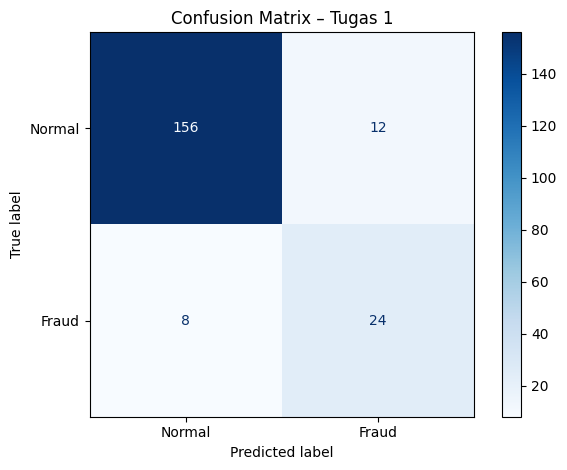

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

TP, TN, FP, FN = 24, 156, 12, 8
cm_t1 = np.array([[TN, FP],
                  [FN, TP]])
print('Confusion matrix:\n', cm_t1)

acc  = (TP + TN) / (TP + TN + FP + FN)
prec = TP / (TP + FP)
rec  = TP / (TP + FN)
f1   = 2 * prec * rec / (prec + rec)
print(f'Accuracy={acc:.3f}; Precision={prec:.3f}; Recall={rec:.3f}; F1={f1:.3f}')

ConfusionMatrixDisplay(cm_t1, display_labels=['Normal','Fraud']).plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix – Tugas 1')
plt.tight_layout()
plt.show()

### c. Interpretasi dalam konteks fraud

- **FP = 12** → 12 transaksi normal salah ditandai sebagai fraud. Dampaknya: pelanggan yang sah terganggu (transaksi ditolak/diblokir), beban kerja tim verifikasi bertambah, dan kepercayaan pelanggan bisa turun. Ini tercermin pada precision 66,7%: dari 36 transaksi yang diberi alarm, hanya 24 yang benar-benar fraud (sekitar 1 dari 3 alarm adalah alarm palsu).

- **FN = 8** → 8 transaksi fraud tidak terdeteksi dan lolos sebagai transaksi normal. Dampaknya: kerugian finansial langsung bagi pelanggan/bank dan risiko reputasi. Ini tercermin pada recall 75%: dari 32 fraud sebenarnya, 8 (25%) lolos.

- **Kesimpulan:** Accuracy 90% tampak tinggi, tetapi karena fraud hanya 32 dari 200 transaksi (16%), accuracy kurang menggambarkan kemampuan deteksi fraud. Dalam kasus fraud, FN umumnya lebih mahal daripada FP, sehingga recall perlu mendapat perhatian lebih. Tetap perlu dijaga agar precision tidak terlalu rendah supaya alarm palsu tidak membanjiri operasional. F1 (0,706) memberi gambaran seimbang antara keduanya.

## Tugas 2 — Verifikasi Python
Jalankan Bagian 4.1–4.5. Lampirkan dataset awal, confusion matrix, perhitungan manual dari
TP/TN/FP/FN aktual, dan hasil scikit-learn. Jelaskan kesesuaian hasil.

### a. Dataset awal (Bagian 4.1)

Dataset sintetis berisi 500 transaksi dengan 4 fitur (`amount`, `hour`, `new_device`, `foreign_ip`) dan label `isFraud`.

|  | amount | hour | new_device | foreign_ip | isFraud |
|---|---:|---:|---:|---:|---:|
| 0 | 201.28 | 9 | 0 | 0 | 0 |
| 1 | 52.46 | 8 | 0 | 0 | 0 |
| 2 | 314.33 | 17 | 1 | 0 | 0 |
| 3 | 380.15 | 3 | 0 | 0 | 0 |
| 4 | 21.09 | 5 | 1 | 0 | 0 |

Distribusi kelas: Normal (0) = 484 dan Fraud (1) = 16 (±3,2%), sehingga dataset sangat tidak seimbang.

### b. Pembagian data dan model (Bagian 4.2)

Data dibagi 70:30 dengan `stratify=y` (data uji = 150 transaksi: 145 normal dan 5 fraud). Model: Decision Tree dengan `max_depth=4` dan `class_weight='balanced'`.

### c. Confusion matrix (Bagian 4.3 dan 4.5)

|  | Prediksi Normal | Prediksi Fraud |
|---|---|---|
| **Aktual Normal** | TN = 113 | FP = 32 |
| **Aktual Fraud** | FN = 3 | TP = 2 |

Nilai aktual: **TP = 2, TN = 113, FP = 32, FN = 3.**

### d. Perhitungan manual dari TP/TN/FP/FN aktual (Bagian 4.4)

- Accuracy = (2 + 113) / 150 = **0,767**
- Precision = 2 / (2 + 32) = **0,059**
- Recall = 2 / (2 + 3) = **0,400**
- F1 = 2 × 0,059 × 0,400 / (0,059 + 0,400) = **0,103**

In [9]:
import pandas as pd

TP, TN, FP, FN = 2, 113, 32, 3
manual = {
    'Accuracy':  (TP + TN) / (TP + TN + FP + FN),
    'Precision': TP / (TP + FP),
    'Recall':    TP / (TP + FN),
}
manual['F1'] = 2 * manual['Precision'] * manual['Recall'] / (manual['Precision'] + manual['Recall'])

sk = {
    'Accuracy':  accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred, zero_division=0),
    'Recall':    recall_score(y_test, y_pred, zero_division=0),
    'F1':        f1_score(y_test, y_pred, zero_division=0),
}
perbandingan = pd.DataFrame({'Manual': manual, 'scikit-learn': sk})
perbandingan['Selisih'] = (perbandingan['Manual'] - perbandingan['scikit-learn']).abs()
print(perbandingan.round(4))

           Manual  scikit-learn  Selisih
Accuracy   0.7667        0.7667      0.0
Precision  0.0588        0.0588      0.0
Recall     0.4000        0.4000      0.0
F1         0.1026        0.1026      0.0


### e. Hasil scikit-learn (Bagian 4.4)

| Metrik | Manual | scikit-learn |
|---|---:|---:|
| Accuracy | 0,767 | 0,7667 |
| Precision | 0,059 | 0,0588 |
| Recall | 0,400 | 0,4000 |
| F1 | 0,103 | 0,1026 |

### f. Kesesuaian hasil

Hasil perhitungan manual dan scikit-learn **sama persis**; perbedaan hanya pada pembulatan (manual 3 desimal, scikit-learn nilai penuh). Hal ini wajar karena keduanya memakai rumus yang sama dan bersumber dari TP, TN, FP, FN yang sama, sehingga perhitungan manual terverifikasi benar.

Hal yang dapat disimpulkan dari hasilnya:

- **Precision sangat rendah (5,9%):** dari 34 transaksi yang ditandai fraud, hanya 2 yang benar-benar fraud, dan 32 lainnya alarm palsu.
- **Recall 40%:** dari 5 fraud sebenarnya, model hanya menangkap 2 dan melewatkan 3.
- **Accuracy 76,7% menyesatkan:** nilainya didominasi 113 TN dari kelas normal yang jumlahnya sangat banyak, sedangkan kemampuan mendeteksi fraud lemah (F1 hanya 0,103).
- Data uji hanya memuat 5 fraud, sehingga satu prediksi saja mengubah recall 20 poin; hasilnya sangat sensitif.

## Tugas 3 — Evaluasi Data Tidak Seimbang
Bandingkan baseline semua normal dan Decision Tree pada Bagian 4.7. Jelaskan mengapa accuracy tinggi
belum tentu menunjukkan kemampuan mendeteksi fraud.

### a. Perbandingan baseline "semua normal" dan Decision Tree (Bagian 4.7)

Data uji: 150 transaksi (145 normal, 5 fraud).

| Metrik | Baseline (semua normal) | Decision Tree |
|---|---:|---:|
| Accuracy | **0,967** | 0,767 |
| Precision kelas Fraud | **0,00** | 0,06 |
| Recall kelas Fraud | **0,00** | **0,40** |
| F1 kelas Fraud | 0,00 | 0,10 |
| Fraud tertangkap | 0 dari 5 | 2 dari 5 |
| Macro avg F1 | 0,49 | 0,48 |

Baseline memprediksi semua transaksi sebagai normal, sehingga TN = 145, FN = 5, TP = 0, FP = 0. Accuracy-nya = 145/150 = 0,967.

In [10]:
baseline = np.zeros(len(y_test), dtype=int)

hasil = pd.DataFrame({
    'Baseline': [accuracy_score(y_test, baseline),
                 precision_score(y_test, baseline, zero_division=0),
                 recall_score(y_test, baseline, zero_division=0),
                 f1_score(y_test, baseline, zero_division=0)],
    'Decision Tree': [accuracy_score(y_test, y_pred),
                      precision_score(y_test, y_pred, zero_division=0),
                      recall_score(y_test, y_pred, zero_division=0),
                      f1_score(y_test, y_pred, zero_division=0)],
}, index=['Accuracy', 'Precision (Fraud)', 'Recall (Fraud)', 'F1 (Fraud)'])
print(hasil.round(3))

                   Baseline  Decision Tree
Accuracy              0.967          0.767
Precision (Fraud)     0.000          0.059
Recall (Fraud)        0.000          0.400
F1 (Fraud)            0.000          0.103


### b. Mengapa accuracy tinggi belum tentu menunjukkan kemampuan mendeteksi fraud

1. **Data sangat tidak seimbang.** Fraud hanya 5 dari 150 data uji (3,3%). Model yang selalu menebak "normal" otomatis benar pada 96,7% data, padahal tidak melakukan deteksi sama sekali.

2. **Accuracy menghitung semua kelas secara setara.** Banyaknya TN dari kelas normal mendominasi nilainya, sehingga kegagalan di kelas minoritas (fraud) hampir tidak terlihat. Baseline mendapat accuracy 0,967 dengan recall fraud 0 dan precision 0, artinya tidak ada satu pun fraud yang tertangkap.

3. **Decision Tree punya accuracy lebih rendah, tetapi lebih berguna untuk deteksi.** Accuracy-nya 0,767 (lebih rendah dari baseline), namun recall fraud 0,40: 2 dari 5 fraud tertangkap, sedangkan baseline 0 dari 5. Penurunan accuracy terjadi karena adanya 32 FP (alarm palsu), yang merupakan harga dari upaya menangkap fraud.

4. **Metrik yang tepat untuk kasus ini adalah precision, recall, dan F1 pada kelas fraud, bukan accuracy.** Pada baseline, metrik-metrik ini langsung menunjukkan nilai 0, sedangkan accuracy menyembunyikannya.

**Catatan:** Decision Tree ini juga belum bagus. Precision-nya hanya 0,06 (dari 34 alarm hanya 2 yang benar) dan recall 0,40 masih rendah. Data uji hanya memuat 5 fraud, sehingga hasilnya sangat sensitif terhadap satu prediksi saja.

**Kesimpulan:** Accuracy tinggi tidak menjamin model mampu mendeteksi fraud, terutama pada data tidak seimbang. Evaluasi harus memakai recall, precision, dan F1 pada kelas fraud, serta mempertimbangkan biaya FN dan FP.

## Tugas 4 — Eksperimen dan Rekomendasi
Uji empat threshold pada Bagian 4.8. Buat tabel precision dan recall, pilih threshold untuk skenario biaya
FN lebih tinggi daripada FP, dan berikan argumentasi berbasis hasil.

### a. Tabel precision dan recall pada empat threshold (Bagian 4.8)

Data uji: 150 transaksi (5 fraud).

| Threshold | Precision | Recall | TP | FP | FN |
|---|---:|---:|---:|---:|---:|
| 0,2 | 0,059 | 0,400 | 2 | 32 | 3 |
| 0,4 | 0,059 | 0,400 | 2 | 32 | 3 |
| 0,5 | 0,059 | 0,400 | 2 | 32 | 3 |
| 0,7 | 0,056 | 0,200 | 1 | 17 | 4 |

(TP, FP, FN diturunkan dari precision/recall: recall 0,4 dari 5 fraud berarti TP = 2 dan precision 0,059 berarti 34 prediksi fraud sehingga FP = 32; recall 0,2 berarti TP = 1 dan precision 0,056 berarti 18 prediksi fraud sehingga FP = 17.)

In [11]:
thresholds = [0.2, 0.4, 0.5, 0.7]
baris = []
for t in thresholds:
    pred = (y_prob >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, pred, labels=[0,1]).ravel()
    baris.append({'Threshold': t,
                  'Precision': precision_score(y_test, pred, zero_division=0),
                  'Recall': recall_score(y_test, pred, zero_division=0),
                  'TP': tp_, 'FP': fp_, 'FN': fn_})
print(pd.DataFrame(baris).round(3).to_string(index=False))

 Threshold  Precision  Recall  TP  FP  FN
       0.2      0.059     0.4   2  32   3
       0.4      0.059     0.4   2  32   3
       0.5      0.059     0.4   2  32   3
       0.7      0.056     0.2   1  17   4


### b. Threshold yang dipilih untuk skenario biaya FN lebih tinggi daripada FP: 0,2

**Argumentasi berbasis hasil:**

1. **Recall adalah prioritas.** Jika FN (fraud lolos) lebih mahal daripada FP (alarm palsu), threshold dipilih untuk memaksimalkan recall dengan precision yang masih dapat diterima. Recall tertinggi pada percobaan ini adalah 0,40 (2 dari 5 fraud tertangkap), dicapai pada threshold 0,2, 0,4, dan 0,5.

2. **Threshold 0,7 paling buruk.** Recall turun menjadi 0,20 (fraud lolos naik dari 3 menjadi 4), sementara precision tidak membaik (0,056, bahkan sedikit lebih rendah dari 0,059). Menaikkan threshold hanya mengurangi alarm palsu (FP turun dari 32 menjadi 17) dengan mengorbankan fraud yang tertangkap, padahal FN yang lebih mahal. Ini tidak sesuai skenario.

3. **Threshold 0,2, 0,4, dan 0,5 menghasilkan metrik identik.** Penyebabnya, Decision Tree dengan `max_depth=4` hanya menghasilkan beberapa nilai probabilitas yang berbeda (satu per daun), sehingga threshold di antara nilai-nilai itu menghasilkan prediksi yang sama. Berdasarkan data ini, ketiganya seri. Saya memilih **0,2** karena merupakan yang paling rendah dan paling sesuai dengan kebijakan "lebih baik salah mengeluarkan alarm daripada kehilangan fraud". Threshold ini juga memberi margin jika probabilitas model berubah pada data baru.

4. **Konsekuensinya diterima.** Pada threshold 0,2 terdapat 32 FP dan precision hanya 0,059, artinya sekitar 94% alarm adalah palsu. Dalam skenario biaya FN lebih tinggi, ini adalah trade-off yang disengaja: biaya 32 verifikasi tambahan dianggap lebih murah daripada kerugian dari fraud yang lolos.

**Catatan dan batasan:**

- Hasil ini hanya berdasar 5 fraud pada data uji, sehingga perbedaan antar-threshold sangat sensitif (satu fraud mengubah recall 20 poin).
- Recall 0,40 masih rendah: 3 dari 5 fraud tetap lolos pada threshold terendah sekalipun. Mengatur threshold saja tidak cukup; perlu perbaikan model (misalnya model probabilistik yang lebih halus, tuning hyperparameter, atau data fraud lebih banyak) dan validasi dengan cross-validation.

**Kesimpulan:** Untuk skenario FN lebih mahal daripada FP, pilih threshold **0,2**, karena recall tertinggi (0,40) dicapai tanpa kehilangan precision dibanding threshold lain, sedangkan threshold 0,7 menurunkan recall tanpa keuntungan berarti.